### Naiver Bayes: Movie Reviews

[Video](https://youtu.be/XZLFVL0RKfs) - [In Colab öffnen](https://colab.research.google.com/github/ktheu/InfoKursN/blob/main/naiverBayes/inhalte/moviereview.ipynb)

Dieses Notebook setzt das Notebook **Naiver Bayes** voraus. Ein Klassifikator soll erkennen, ob eine Filmkritik
positiv oder negativ ist (**Sentiment-Analyse**). Das Notebook braucht `pandas`, `matplotlib` und `scikit-learn`, in
Google Colab sind sie installiert.

#### Die Daten

Der *Sentiment Polarity Dataset* von Bo Pang und Lillian Lee (Cornell University, 2004) enthält 2000 englische
Filmkritiken, 1000 positive und 1000 negative. Wir laden ihn aus dem Datenarchiv der Python-Bibliothek NLTK, die ihn
mit Erlaubnis der Autoren verteilt (eine ZIP-Datei mit einer Textdatei pro Kritik, etwa 4 MB).

In [1]:
import io
import urllib.request
import zipfile

import pandas as pd

url = 'https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/packages/corpora/movie_reviews.zip'
archiv = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
zeilen = []
for name in sorted(archiv.namelist()):
    if name.endswith('.txt'):
        label = name.split('/')[1]                  # movie_reviews/pos/cv000_29590.txt
        zeilen.append((label, archiv.read(name).decode('utf-8')))
df = pd.DataFrame(zeilen, columns=['label', 'review'])
df['label'].value_counts()

label
neg    1000
pos    1000
Name: count, dtype: int64

In [2]:
print(df.iloc[0]['review'][:600])

plot : two teen couples go to a church party , drink and then drive . 
they get into an accident . 
one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . 
what's the deal ? 
watch the movie and " sorta " find out . . . 
critique : a mind-fuck movie for the teen generation that touches on a very cool idea , but presents it in a very bad package . 
which is what makes this review an even harder one to write , since i generally applaud films which attempt to break the mold , mess with your head and such ( lost highway & memento ) , but there are good an


Die Texte sind schon kleingeschrieben, Satzzeichen sind durch Leerzeichen abgetrennt.

#### Training und Test

80 % der Kritiken nehmen wir zum Trainieren, mit den übrigen 20 % prüfen wir, wie oft der Klassifikator richtig liegt.

In [3]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

X_train, X_test, y_train, y_test = train_test_split(df['review'], df['label'], test_size=0.2, random_state=101)
vectorizer = CountVectorizer()
X_train_v = vectorizer.fit_transform(X_train)
print(X_train_v.shape)

(1600, 36159)


1600 Kritiken mit zusammen über 30 000 verschiedenen Wörtern. Jede Kritik ist ein Vektor mit so vielen Einträgen, die
meisten davon 0.

Genauigkeit: 0.8275


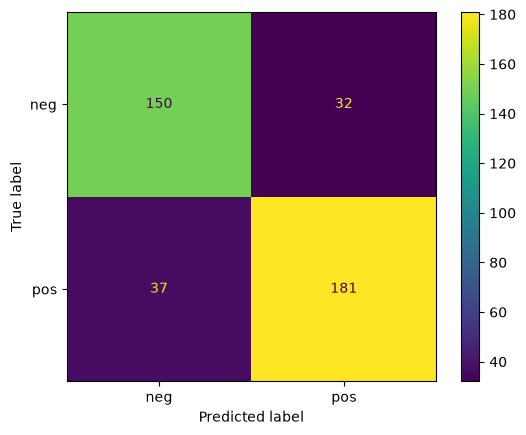

In [4]:
modell = MultinomialNB()
modell.fit(X_train_v, y_train)
X_test_v = vectorizer.transform(X_test)
y_pred = modell.predict(X_test_v)

from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print('Genauigkeit:', accuracy_score(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

Die **Konfusionsmatrix** zeigt, wie viele negative und positive Kritiken richtig (Diagonale) und falsch eingeordnet
wurden.

#### Welche Wörter sprechen für positiv, welche für negativ?

Für jedes Wort vergleichen wir $\ln P(\text{Wort} \mid \text{pos}) - \ln P(\text{Wort} \mid \text{neg})$. Ist der
Wert groß, spricht das Wort für eine positive Kritik. Wir nehmen nur Wörter, die mindestens 100-mal vorkommen.

In [5]:
woerter = vectorizer.get_feature_names_out()
haeufigkeit = X_train_v.sum(axis=0).A1
log_p = pd.DataFrame(modell.feature_log_prob_.T, index=woerter, columns=modell.classes_)
log_p['differenz'] = log_p['pos'] - log_p['neg']
log_p = log_p[haeufigkeit >= 100].sort_values('differenz')
print('negativ:', ', '.join(log_p.index[:15]))
print('positiv:', ', '.join(log_p.index[-15:][::-1]))

negativ: godzilla, ridiculous, worst, waste, boring, terrible, stupid, dull, batman, mess, west, harry, supposed, robin, bad
positiv: truman, titanic, cameron, memorable, jackie, spielberg, wars, excellent, political, perfectly, war, animation, effective, brown, wonderful


Neben Wörtern wie *worst*, *boring*, *terrible* bzw. *excellent*, *wonderful*, *memorable* stehen dort auch Filmtitel
und Namen wie *godzilla*, *titanic* oder *spielberg*: Über diese Filme wurde in den Trainingsdaten eher schlecht bzw.
gut geschrieben. Der Klassifikator weiß nicht, was die Wörter bedeuten, er zählt nur.

In [6]:
eigene = ['a wonderful and moving film with brilliant actors',
          'boring , predictable and a complete waste of time',
          'not bad at all']
modell.predict(vectorizer.transform(eigene))

array(['pos', 'neg', 'neg'], dtype='<U3')

Bei *not bad at all* zeigt sich eine Schwäche des Bag of Words: *not* und *bad* werden einzeln gezählt, die Verneinung
geht verloren.

### Varianten vergleichen

Man kann **Stoppwörter** (häufige Wörter wie *the*, *and*, *of*) weglassen oder statt der Anzahlen **TF-IDF-Werte**
nehmen (siehe unten). Ob das hilft, prüfen wir mit Kreuzvalidierung: 5-mal wird mit 80 % trainiert und mit den übrigen
20 % getestet, jedes Mal mit anderen 20 %. `make_pipeline` verbindet Vektorisierer und Klassifikator, damit der
Wortschatz jedes Mal nur aus den Trainingsdaten gelernt wird.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

varianten = {
    'Anzahlen': CountVectorizer(),
    'Anzahlen ohne Stoppwörter': CountVectorizer(stop_words='english'),
    'TF-IDF': TfidfVectorizer(),
    'TF-IDF ohne Stoppwörter': TfidfVectorizer(stop_words='english'),
}
for name, v in varianten.items():
    werte = cross_val_score(make_pipeline(v, MultinomialNB()), df['review'], df['label'], cv=5)
    print(f'{name:27} {werte.mean():.3f}  {werte.round(3)}')

Anzahlen                    0.812  [0.81  0.825 0.81  0.825 0.79 ]


Anzahlen ohne Stoppwörter   0.804  [0.798 0.818 0.805 0.822 0.78 ]


TF-IDF                      0.812  [0.808 0.825 0.8   0.825 0.805]


TF-IDF ohne Stoppwörter     0.815  [0.81  0.825 0.81  0.825 0.802]


Die Unterschiede zwischen den Varianten sind klein, die Genauigkeit liegt um 80 %. Die Schwankung zwischen den fünf
Durchläufen ist ähnlich groß wie die Unterschiede.

### Exkurs: TF-IDF

Ein Wort, das in fast allen Dokumenten vorkommt, sagt wenig über ein einzelnes Dokument aus. **TF-IDF** gewichtet die
Wörter deshalb:

- **TF** (term frequency): wie oft das Wort im Dokument vorkommt
- **IDF** (inverse document frequency): wie selten das Wort in allen Dokumenten ist. scikit-learn rechnet

$$\text{IDF} = \ln \frac{1 + n}{1 + \text{df}} + 1$$

mit der Anzahl $n$ der Dokumente und der Anzahl $\text{df}$ der Dokumente, die das Wort enthalten.

Der Wert ist $\text{TF} \cdot \text{IDF}$. Danach wird jeder Dokumentvektor auf die Länge 1 normiert.

In [8]:
texte = ['I love cats', 'I love dogs', 'Dogs and cats are great']
tfidf = TfidfVectorizer(stop_words='english')
X = tfidf.fit_transform(texte)
pd.DataFrame(X.toarray(), columns=tfidf.get_feature_names_out()).round(4)

,cats,dogs,great,love
0,0.7071,0.0000,0.0000,0.7071
1,0.0000,0.7071,0.0000,0.7071
2,0.5179,0.5179,0.6809,0.0000


Nach dem Entfernen der Stoppwörter bleiben *cats*, *dogs*, *great* und *love*. Nachrechnen für den ersten Text
*I love cats*: *love* und *cats* kommen in je 2 der 3 Texte vor.

In [9]:
import math

idf = math.log((1 + 3) / (1 + 2)) + 1      # für love und für cats
v = [idf, 0, 0, idf]                        # cats, dogs, great, love
laenge = math.sqrt(sum(x * x for x in v))
[round(x / laenge, 4) for x in v]

[0.7071, 0.0, 0.0, 0.7071]

*great* kommt nur im dritten Text vor und bekommt dort einen höheren Wert als *cats* und *dogs*, die es auch in
anderen Texten gibt.

### Zusammenfassung

- Mit **Bag of Words** und **naivem Bayes** erkennt ein einfaches Programm bei etwa 80 % der Filmkritiken, ob sie
  positiv oder negativ sind.
- Geprüft wird mit **Testdaten**, die beim Training nicht benutzt wurden, verlässlicher mit **Kreuzvalidierung**.
- Der Klassifikator versteht die Wörter nicht. Verneinungen wie *not bad* oder Ironie erkennt er nicht.
- **TF-IDF** gewichtet Wörter nach ihrer Seltenheit, **Stoppwörter** sind häufige Wörter ohne viel Aussage.